In [8]:
from matplotlib import cm
import matplotlib.pyplot as plt
import numpy as np

from fluids.navier import NavierStokesSolver

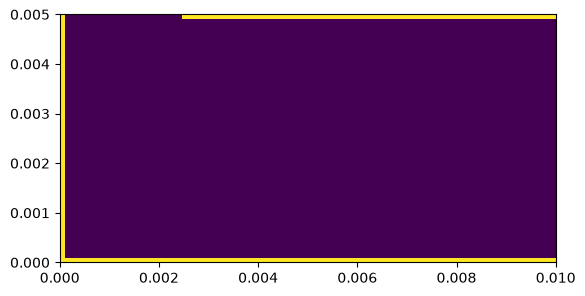

In [14]:
# physical parameters
rho = 1000 # kgm^-3
nu = 0.001/rho # Pa s / kgm^-3

Lx, Ly = 0.01, 0.005 # m

Pmax = 0.01 # Pa

Nx, Ny = 101, 51

dx = Lx/(Nx-1)
dy = Ly/(Ny-1)

X, Y = np.mgrid[0:Nx:1, 0:Ny:1]
X = X*dx
Y = Y*dy

u = np.zeros_like(X)
v = np.zeros_like(X)
p = np.zeros_like(X)

p[:Nx//4, -1] = Pmax
p[-1, :] = 0.0

boundary_mesh = np.zeros_like(X, dtype=bool)
boundary_mesh[:Nx//4, -1] = False
boundary_mesh[-1, :] = False
boundary_mesh[0, :] = True
boundary_mesh[:, 0] = True
boundary_mesh[Nx//4:, -1] = True

plt.imshow(boundary_mesh.T, origin="lower", extent=[X[0, 0], X[-1, -1], Y[0, 0], Y[-1, -1]], aspect="equal")

solver = NavierStokesSolver(
    boundary_mesh=boundary_mesh, Pmax=Pmax, 
    p=p, u=u, v=v, 
    nu=nu, rho=rho, 
    Lx=Lx, Ly=Ly, Nx=Nx, Ny=Ny
    )

In [15]:
print("Pmax:", Pmax)
print("Lx, Ly:", Lx, Ly)
print("rho:", rho)
print("nu:", nu)
print("v_max:", solver.v_max)

Pmax: 0.01
Lx, Ly: 0.01 0.005
rho: 1000
nu: 1e-06
v_max: 0.003125


In [16]:
u, v, p_solve = solver.solve_NS(t_end=15)

Flow achieved steady state at t = 13.66s
velocity residual = 1.413014838564607e-07
norm(u) = 0.08453764, norm(v) = 0.05375926
Courant number: 0.00558500


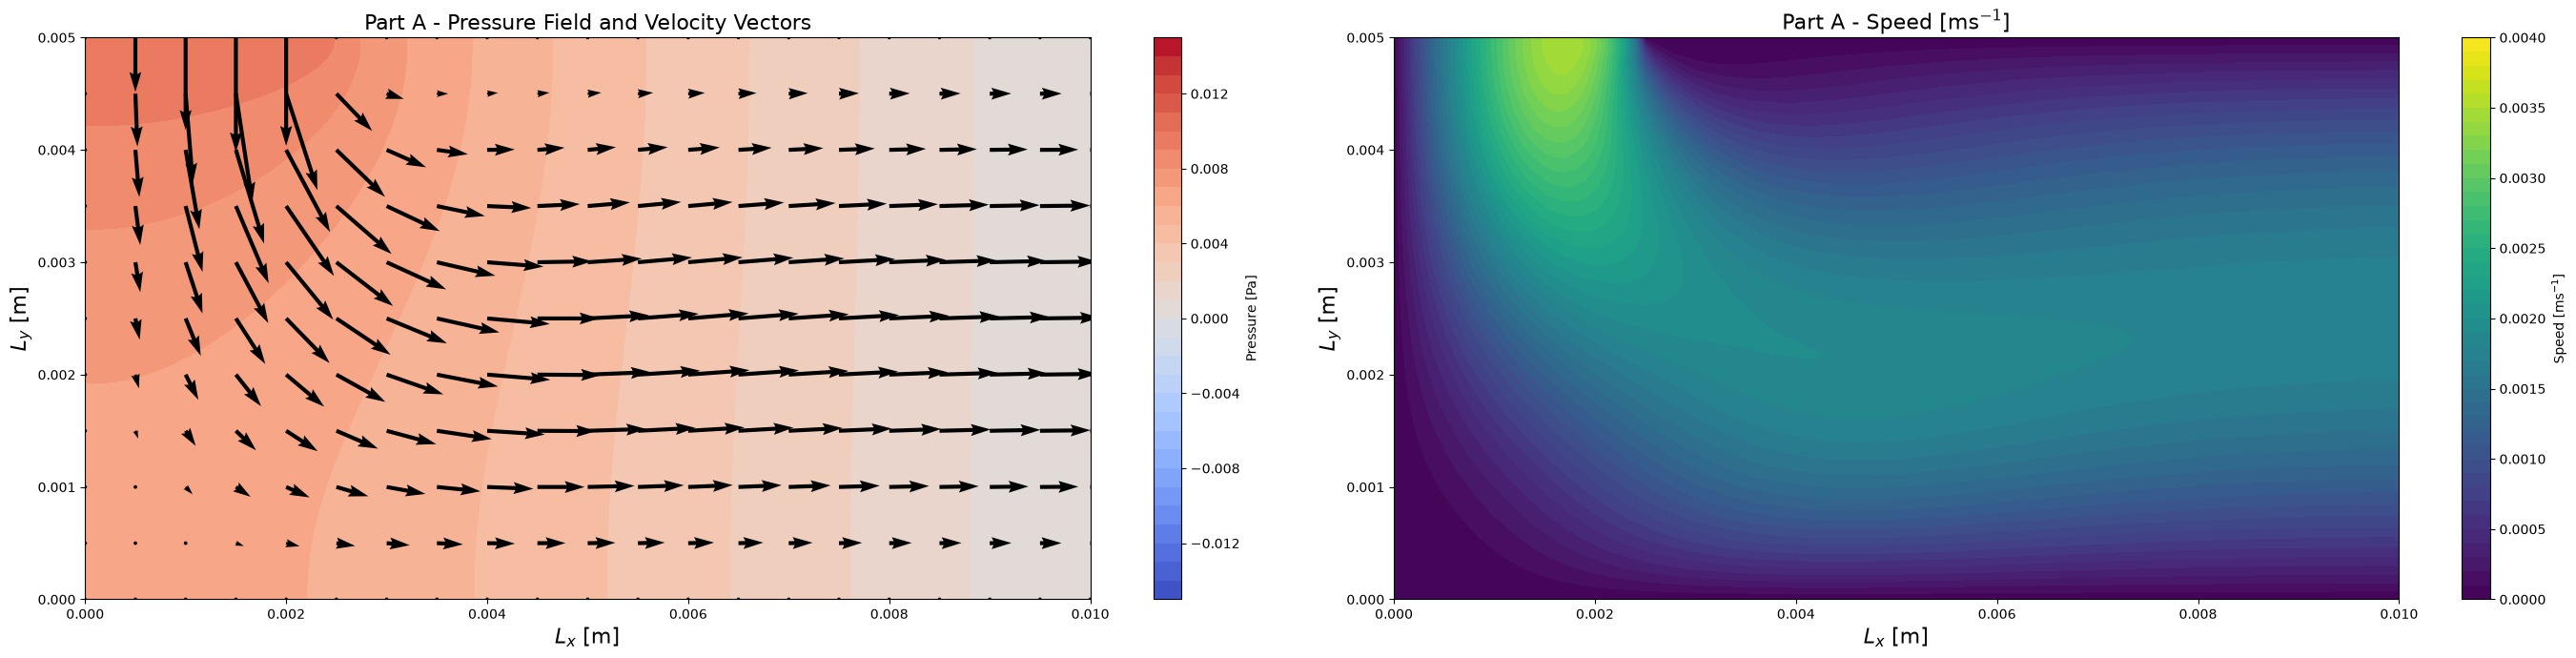

In [17]:
# set up figure
fig = plt.figure(figsize=(28, 7))
ax1 = fig.add_subplot(121)
cont = ax1.contourf(X,Y, p, cmap=cm.coolwarm,
                    levels=np.arange(-0.015, 0.015+0.001, 0.001))
fig.colorbar(cont, label='Pressure [Pa]')
# don't plot at every gird point - every 5th
ax1.quiver(X[::5,::5],Y[::5,::5],u[::5,::5],v[::5,::5])
ax1.set_xlabel('$L_x$ [m]', fontsize=16)
ax1.set_ylabel('$L_y$ [m]', fontsize=16)
ax1.set_title('Part A - Pressure Field and Velocity Vectors', fontsize=16)

ax1 = fig.add_subplot(122)
cont = ax1.contourf(X,Y,np.sqrt(u*u+v*v), cmap=cm.viridis,
                    levels=np.arange(0,0.004+0.0001, 0.0001))
fig.colorbar(cont, label='Speed [ms$^{-1}$]')
ax1.set_xlabel('$L_x$ [m]', fontsize=16)
ax1.set_ylabel('$L_y$ [m]', fontsize=16)
ax1.set_title('Part A - Speed [ms$^{-1}$]', fontsize=16)

plt.tight_layout()

In [ ]:
# physical parameters
rho = 1000 # kgm^-3
nu = 0.001/rho # Pa s / kgm^-3


Nx, Ny = 101, 101
dx, dy = 0.1, 0.1 # m

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy

Lx = x[-1]
Ly = y[-1]

X, Y = np.meshgrid(x, y, indexing="ij")

p = np.zeros_like(X)

p_exact = np.cos(np.pi * X / Lx) * np.cos(np.pi * Y / Ly)

f = -((np.pi / Lx) ** 2 + (np.pi / Ly) ** 2) * p_exact

solver = NavierStokesSolver(
    Pmax=1, p=p, u=None, v=None, nu=nu, rho=rho, Lx=Lx, Ly=Ly, Nx=Nx, Ny=Ny
    )

In [3]:
p_solve = solver.pressure_poisson_jacobi(RHS=f)

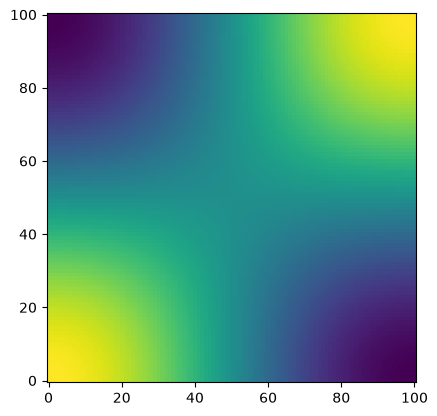

In [4]:
plt.imshow(p_solve, cmap="viridis", origin="lower")

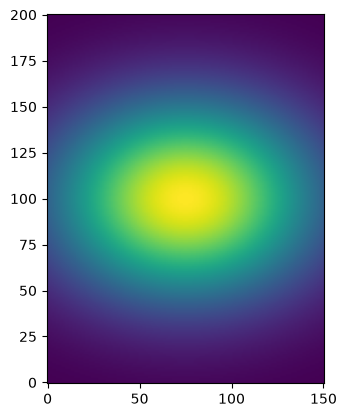

In [ ]:
# physical parameters
rho = 1000 # kgm^-3
nu = 0.001/rho # Pa s / kgm^-3

Nx, Ny = 201, 151
dx, dy = 200, 150

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy

Lx = x[-1]
Ly = y[-1]

X, Y = np.meshgrid(x, y, indexing="ij")

u = np.zeros_like(X)
v = np.zeros_like(X)
p = np.zeros_like(X)

Pmax = 1.0

# Gaussian pressure anomaly
x0 = Lx / 2
y0 = Ly / 2
sigma = min(Lx, Ly) / 3

p = Pmax * np.exp(-((X - x0)**2 + (Y - y0)**2) / (2 * sigma**2))

solver = NavierStokesSolver(
    Pmax=Pmax, p=p, u=u, v=v, nu=nu, rho=rho, Lx=Lx, Ly=Ly, Nx=Nx, Ny=Ny, logs=True
    )

plt.imshow(p, cmap="viridis", origin="lower")

In [6]:
u, v, p_solve = solver.solve_NS(t_end=0.1, output=True, output_freq=100)


Time = 0.00000008
PPE solve iterations = 14263
velocity residual = 0.0
Flow achieved steady state at t = 0.00s
velocity residual = 0.0
norm(u) = 0.00000000, norm(v) = 0.00000000
Courant number: 0.00000000


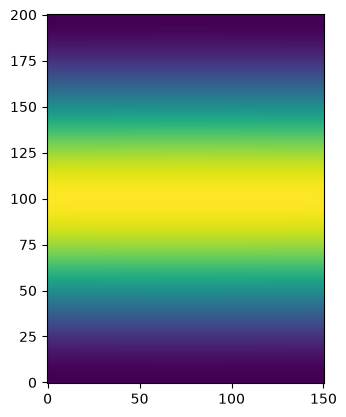

In [7]:
plt.imshow(p_solve, cmap="viridis", origin="lower")